In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
from sklearn.model_selection import train_test_split

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression

In [8]:
sp_500 = pd.read_csv('/Users/maheshg/Dropbox/Sample Datasets Kaggle/S_P_100_Dataset/SP500_Historical_Data.csv')

In [9]:
sp_500.head()

,Ticker,Date,Open,High,Low,Close,Adj.Close,Volume
0,A,2023-01-03,151.960007,153.130005,148.470001,150.039993,146.415833,1414300.0
1,AAPL,2023-01-03,130.279999,130.899994,124.169998,125.070000,122.982697,112117500.0
2,ABBV,2023-01-03,162.039993,163.020004,160.809998,162.380005,143.135178,4937500.0
3,ABNB,2023-01-03,87.385002,88.139999,84.300003,84.900002,84.900002,3901200.0
4,ABT,2023-01-03,110.510002,111.330002,108.750000,109.580002,102.208000,4171900.0


In [10]:
sp_500.size

3818592

In [13]:
sp_500.describe()

,Open,High,Low,Close,Adj.Close,Volume
count,477287.000000,477287.000000,477286.000000,477001.000000,477001.000000,4.772870e+05
mean,199.109861,201.566398,196.613331,199.088045,195.641256,6.243712e+06
std,391.102738,395.737082,386.477700,390.962167,390.343029,2.001084e+07
min,0.876000,0.918000,0.846000,0.882000,0.882000,0.000000e+00
25%,67.029999,67.879997,66.199997,67.040001,64.870155,1.153600e+06
50%,120.269997,121.800003,118.800003,120.300003,116.755188,2.417900e+06
75%,223.556625,226.160004,220.889999,223.550003,219.389999,5.507200e+06
max,9914.169922,9964.769531,9794.000000,9924.400391,9924.400391,1.543911e+09


Define the problem : Let us target the next day stock price which is target as close 

In [14]:
target = sp_500['Close']

In [16]:
target2 = sp_500['Adj.Close']

Creating the features as an object 

In [17]:
features = sp_500.drop(['Open', 'High','Low', 'Close'], axis=1)

Peform the Exploratory Data Analysis

In [18]:
sp_500.isnull().sum()

Ticker         0
Date           0
Open          37
High          37
Low           38
Close        323
Adj.Close    323
Volume        37
dtype: int64

In [19]:
sp_500.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 477324 entries, 0 to 477323
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Ticker     477324 non-null  object 
 1   Date       477324 non-null  object 
 2   Open       477287 non-null  float64
 3   High       477287 non-null  float64
 4   Low        477286 non-null  float64
 5   Close      477001 non-null  float64
 6   Adj.Close  477001 non-null  float64
 7   Volume     477287 non-null  float64
dtypes: float64(6), object(2)
memory usage: 29.1+ MB


In [20]:
sp_500.describe()

,Open,High,Low,Close,Adj.Close,Volume
count,477287.000000,477287.000000,477286.000000,477001.000000,477001.000000,4.772870e+05
mean,199.109861,201.566398,196.613331,199.088045,195.641256,6.243712e+06
std,391.102738,395.737082,386.477700,390.962167,390.343029,2.001084e+07
min,0.876000,0.918000,0.846000,0.882000,0.882000,0.000000e+00
25%,67.029999,67.879997,66.199997,67.040001,64.870155,1.153600e+06
50%,120.269997,121.800003,118.800003,120.300003,116.755188,2.417900e+06
75%,223.556625,226.160004,220.889999,223.550003,219.389999,5.507200e+06
max,9914.169922,9964.769531,9794.000000,9924.400391,9924.400391,1.543911e+09


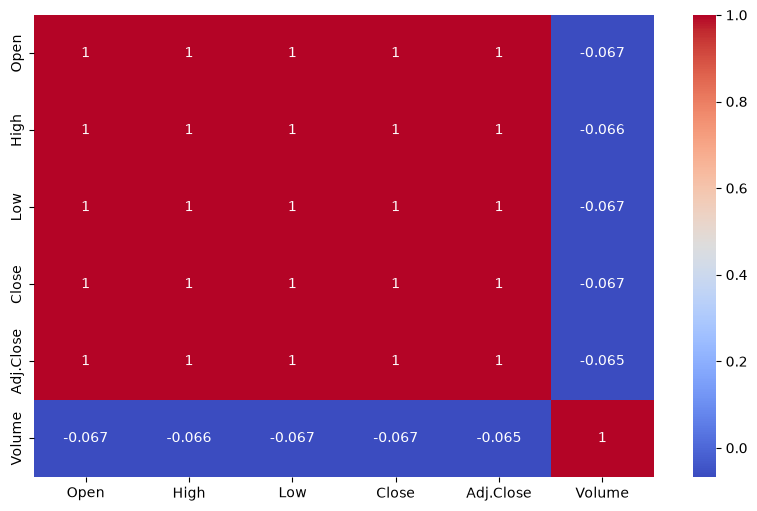

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.heatmap(
    sp_500.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm'
)
plt.show()

Feature Engineering

In [25]:
sp_500['Daily Return'] = sp_500['Close'].pct_change()

/var/folders/bt/k7t4mr2j6kq79jv3vbj756z80000gn/T/ipykernel_23849/2633293056.py:1: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  sp_500['Daily Return'] = sp_500['Close'].pct_change()


In [26]:
sp_500.head()

,Ticker,Date,Open,High,Low,Close,Adj.Close,Volume,Daily Return
0,A,2023-01-03,151.960007,153.130005,148.470001,150.039993,146.415833,1414300.0,NaN
1,AAPL,2023-01-03,130.279999,130.899994,124.169998,125.070000,122.982697,112117500.0,-0.166422
2,ABBV,2023-01-03,162.039993,163.020004,160.809998,162.380005,143.135178,4937500.0,0.298313
3,ABNB,2023-01-03,87.385002,88.139999,84.300003,84.900002,84.900002,3901200.0,-0.477152
4,ABT,2023-01-03,110.510002,111.330002,108.750000,109.580002,102.208000,4171900.0,0.290695


Creating Moving Average in the current dataset 

In [27]:
sp_500['Moving_Average_5'] = sp_500['Close'].rolling(window=5).mean()
sp_500['Moving_Average_20'] = sp_500['Close'].rolling(window=20).mean()
sp_500['Moving_Average_50'] = sp_500['Close'].rolling(window=50).mean()

Creating Volatility in the current dataset 

In [28]:
sp_500['Volatality_20'] = sp_500['Close'].rolling(window=20).std()

In [29]:
sp_500.head()

,Ticker,Date,Open,High,Low,Close,Adj.Close,Volume,Daily Return,Moving_Average_5,Moving_Average_20,Moving_Average_50,Volatality_20
0,A,2023-01-03,151.960007,153.130005,148.470001,150.039993,146.415833,1414300.0,NaN,NaN,NaN,NaN,NaN
1,AAPL,2023-01-03,130.279999,130.899994,124.169998,125.070000,122.982697,112117500.0,-0.166422,NaN,NaN,NaN,NaN
2,ABBV,2023-01-03,162.039993,163.020004,160.809998,162.380005,143.135178,4937500.0,0.298313,NaN,NaN,NaN,NaN
3,ABNB,2023-01-03,87.385002,88.139999,84.300003,84.900002,84.900002,3901200.0,-0.477152,NaN,NaN,NaN,NaN
4,ABT,2023-01-03,110.510002,111.330002,108.750000,109.580002,102.208000,4171900.0,0.290695,126.394,NaN,NaN,NaN


In [30]:
sp_500.isna().sum()

Ticker                  0
Date                    0
Open                   37
High                   37
Low                    38
Close                 323
Adj.Close             323
Volume                 37
Daily Return            1
Moving_Average_5      681
Moving_Average_20    1151
Moving_Average_50    1982
Volatality_20        1151
dtype: int64

Removing the NAN values from the dataset 

In [31]:
sp_500 = sp_500.dropna()

In [32]:
sp_500.head()

,Ticker,Date,Open,High,Low,Close,Adj.Close,Volume,Daily Return,Moving_Average_5,Moving_Average_20,Moving_Average_50,Volatality_20
49,AZO,2023-01-03,2441.510010,2454.709961,2420.320068,2431.060059,2431.060059,134500.0,15.524335,616.746014,235.333779,180.660912,523.554459
50,BA,2023-01-03,192.949997,197.179993,192.399994,195.389999,195.389999,8624600.0,-0.919628,619.182013,234.369779,181.567912,523.612255
51,BAC,2023-01-03,33.230000,34.090000,33.209999,33.509998,30.640945,35221500.0,-0.828497,595.064011,231.754279,179.736712,524.523186
52,BALL,2023-01-03,51.549999,52.570000,51.259998,51.970001,49.472908,1248800.0,0.550880,571.810011,232.841404,177.528512,524.105885
53,BAX,2023-01-03,50.400002,51.360001,50.110001,51.040001,47.277454,2787400.0,-0.017895,552.594012,220.422404,176.851312,525.386424


Perform the train and test split 

In [33]:
X = sp_500[
    ['Open', 
     'High', 
     'Low', 
     'Volume', 
     'Moving_Average_5', 
     'Moving_Average_20', 
     'Moving_Average_50', 
     'Volatality_20']]

In [34]:
y = sp_500['Close']

In [35]:
from sklearn.model_selection import train_test_split

In [36]:
split = int(0.8 * len(sp_500))

In [37]:
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

In [39]:
y_train.shape, y_test.shape

((380273,), (95069,))

In [40]:
y_train.head()

49    2431.060059
50     195.389999
51      33.509998
52      51.970001
53      51.040001
Name: Close, dtype: float64

In [41]:
y_test.head()

380372    417.320007
380373     65.400002
380374    459.790009
380375    205.029999
380376    116.980003
Name: Close, dtype: float64

Feature Scaling is required for Linear Regression, SVR, Neural Networks

In [42]:
from sklearn.preprocessing import StandardScaler

In [43]:
scaler = StandardScaler()

In [49]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Building the Linear Regression

In [50]:
from sklearn.linear_model import LinearRegression

In [51]:
lr = LinearRegression()

In [52]:
lr.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[-203.52, 289.99, 305.5 ,..., 0.1 , 0.01, -0.12]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,190.2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,8
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](8,)","[1189.46, 908.66, 614.09,..., 162.07, 5.57, 4.79]"


Predict the Values 

In [53]:
pred_lr = lr.predict(X_test_scaled)

Evaluate the values 

In [54]:
from sklearn.metrics import mean_squared_error, r2_score,mean_absolute_error

In [55]:
mae = mean_absolute_error(y_test, pred_lr)

mean_squared_error is depreciated, hence using alternate function which is square root of mean squared error via numpy.

In [58]:
rmse = np.sqrt(mean_squared_error(y_test, pred_lr))

In [59]:
r2= r2_score(y_test, pred_lr)

In [60]:
print(f'Mean Absolute Error: {mae}')
print(f'Root Mean Squared Error: {rmse}')
print(f'R-squared: {r2}')

Mean Absolute Error: 1.6328736220614666
Root Mean Squared Error: 4.176706918051465
R-squared: 0.9998830371828158


Model 2- Random Forest Regressor 

In [61]:
from sklearn.ensemble import RandomForestRegressor

In [62]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)

In [ ]:
pred_rf = rf.predict(X_test_scaled)